# PHÂN TÍCH KHÁM PHÁ DỮ LIỆU ĐÁNH GIÁ TMĐT (EDA)

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
PROC_DIR = os.path.join(ROOT, 'data', 'processed')
FIG_DIR = os.path.join(ROOT, 'reports', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

In [3]:
#Chỉ nạp tập train sạch để phân tích EDA, tuyệt đối không nhìn dev/test
df_train = pd.read_csv(os.path.join(PROC_DIR, 'train_clean.csv'))

In [4]:
df_train.shape

(7762, 24)

In [5]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 7762 entries, 0 to 7761
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   index              7762 non-null   int64
 1   sentence           7762 non-null   str  
 2   n_star             7762 non-null   int64
 3   date_time          7762 non-null   str  
 4   label              7762 non-null   str  
 5   sentiment          7762 non-null   int64
 6   aspect_group       7762 non-null   int64
 7   asp_0              7762 non-null   int64
 8   asp_1              7762 non-null   int64
 9   asp_2              7762 non-null   int64
 10  asp_3              7762 non-null   int64
 11  asp_4              7762 non-null   int64
 12  all_aspects        7762 non-null   str  
 13  absa_0             7762 non-null   int64
 14  absa_1             7762 non-null   int64
 15  absa_2             7762 non-null   int64
 16  absa_3             7762 non-null   int64
 17  absa_4             7762 n

In [6]:
df_train.head()

,index,sentence,n_star,date_time,label,sentiment,aspect_group,asp_0,asp_1,asp_2,...,absa_1,absa_2,absa_3,absa_4,has_conflict,conflict_with_neg,conflict_groups,sentence_clean,is_no_content,sentence_seg
0,0,Mới mua máy này Tại thegioididong thốt nốt cảm...,5,2 tuần trước,{CAMERA#Positive};{FEATURES#Positive};{BATTERY...,2,2,1,1,1,...,3,3,3,3,False,False,NaN,Mới mua máy này Tại thegioididong thốt nốt cảm...,False,Mới mua máy này Tại thegioididong thốt_nốt cảm...
1,1,Pin kém còn lại miễn chê mua 8/3/2019 tình trạ...,5,14/09/2019,{BATTERY#Negative};{GENERAL#Positive};{OTHERS};,1,2,0,0,1,...,0,1,0,3,False,False,NaN,Pin kém còn lại miễn chê mua 8/3/2019 tình trạ...,False,Pin kém còn lại miễn chê mua 8 / 3 / 2019 tình...
2,2,Sao lúc gọi điện thoại màn hình bị chấm nhỏ nh...,3,17/08/2020,{FEATURES#Negative};,0,0,1,0,0,...,0,0,0,0,False,False,NaN,Sao lúc gọi điện thoại màn hình bị chấm nhỏ nh...,False,Sao lúc gọi điện_thoại màn_hình bị chấm nhỏ nh...
3,3,"Mọi người cập nhật phần mềm lại , nó sẽ bớt tố...",3,29/02/2020,{FEATURES#Negative};{BATTERY#Neutral};{GENERAL...,1,0,1,0,1,...,0,2,0,2,False,False,NaN,"Mọi người cập nhật phần mềm lại , nó sẽ bớt tố...",False,"Mọi người cập_nhật phần_mềm lại , nó sẽ bớt tố..."
4,4,"Mới mua Sài được 1 tháng thấy pin rất trâu, Sà...",5,4/6/2020,{BATTERY#Positive};{PERFORMANCE#Positive};{SER...,2,3,1,0,1,...,0,3,1,0,False,False,NaN,"Mới mua Sài được 1 tháng thấy pin rất trâu, Sà...",False,"Mới mua Sài được 1 tháng thấy pin rất trâu , S..."


## 1. PHÂN BỐ CẢM XÚC, KHÍA CẠNH VÀ ĐA NHÃN

In [7]:
#Thống kê tần suất 3 lớp cảm xúc thuần túy
df_train['sentiment'].value_counts().sort_index()

sentiment
0    2515
1    1521
2    3726
Name: count, dtype: int64

In [8]:
#Thống kê tần suất khía cạnh chính (primary aspect_group)
df_train['aspect_group'].value_counts().sort_index()

aspect_group
0    3185
1     934
2    1639
3    1095
4     909
Name: count, dtype: int64

In [9]:
#Thống kê tần suất đa nhãn asp_0..asp_4 và số khía cạnh trung bình mỗi câu
asp_cols = ['asp_0', 'asp_1', 'asp_2', 'asp_3', 'asp_4']
df_train[asp_cols].sum()

asp_0    5483
asp_1    2686
asp_2    3595
asp_3    3508
asp_4    6138
dtype: int64

In [10]:
df_train[asp_cols].sum(axis=1).value_counts().sort_index()

1    1006
2    2408
3    2320
4    1512
5     516
Name: count, dtype: int64

In [11]:
#Thống kê phân bố số sao đánh giá của khách hàng
df_train['n_star'].value_counts().sort_index()

n_star
1    1268
2     563
3    1011
4    1265
5    3655
Name: count, dtype: int64

## 2. BIỂU ĐỒ PHÂN BỐ CẢM XÚC VÀ KHÍA CẠNH

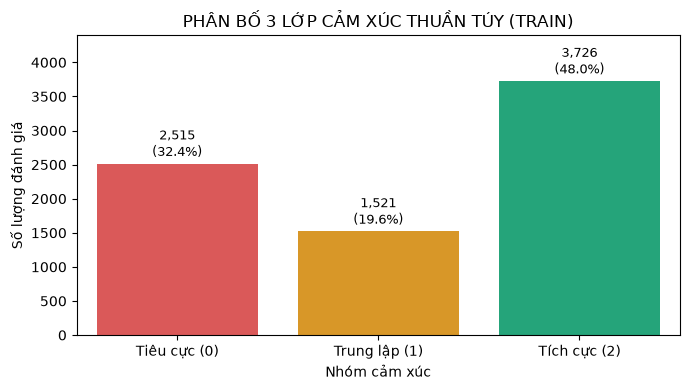

In [12]:
#Vẽ biểu đồ phân bố 3 lớp cảm xúc kèm nhãn trục rõ ràng
plt.figure(figsize=(7, 4))
sent_names = ['Tiêu cực (0)', 'Trung lập (1)', 'Tích cực (2)']
counts = df_train['sentiment'].value_counts().sort_index()
ax = sns.barplot(x=sent_names, y=counts.values, hue=sent_names, legend=False, palette=['#EF4444', '#F59E0B', '#10B981'])
for bar, val in zip(ax.patches, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 50, f'{val:,}\n({val/len(df_train):.1%})', ha='center', va='bottom', fontsize=9)
plt.ylim(0, counts.max() * 1.18)
plt.title('PHÂN BỐ 3 LỚP CẢM XÚC THUẦN TÚY (TRAIN)')
plt.xlabel('Nhóm cảm xúc')
plt.ylabel('Số lượng đánh giá')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_sentiment_dist.png'), dpi=300)
plt.show()

In [13]:
#Sắp xếp nhóm khía cạnh giảm dần theo tần suất và tô màu phân biệt từng nhóm
asp_label_map = {
    0: 'Hiệu năng & Cấu hình',
    1: 'Màn hình & Camera',
    2: 'Thời lượng Pin & Sạc',
    3: 'Giá cả & Hậu mãi',
    4: 'Thiết kế & Tổng quan',
}
asp_palette = {
    'Hiệu năng & Cấu hình': '#2563EB',
    'Thời lượng Pin & Sạc': '#10B981',
    'Giá cả & Hậu mãi': '#F59E0B',
    'Màn hình & Camera': '#8B5CF6',
    'Thiết kế & Tổng quan': '#64748B',
}
counts_asp = df_train['aspect_group'].value_counts()
asp_names_sorted = [asp_label_map[i] for i in counts_asp.index]

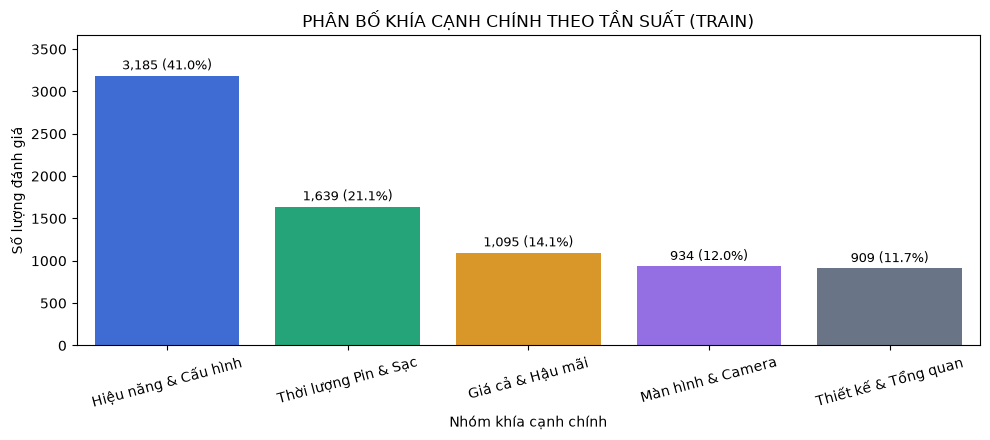

In [14]:
#Vẽ biểu đồ phân bố khía cạnh chính đã sắp xếp theo tần suất
plt.figure(figsize=(10, 4.5))
ax = sns.barplot(x=asp_names_sorted, y=counts_asp.values, hue=asp_names_sorted, legend=False, palette=asp_palette)
for bar, val in zip(ax.patches, counts_asp.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 40, f'{val:,} ({val/len(df_train):.1%})', ha='center', va='bottom', fontsize=9)
plt.ylim(0, counts_asp.max() * 1.15)
plt.title('PHÂN BỐ KHÍA CẠNH CHÍNH THEO TẦN SUẤT (TRAIN)')
plt.xlabel('Nhóm khía cạnh chính')
plt.ylabel('Số lượng đánh giá')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_aspect_dist.png'), dpi=300, bbox_inches='tight')
plt.show()

## 3. TƯƠNG QUAN SỐ SAO VÀ CẢM XÚC (MÂU THUẪN SAO THẬT)

In [15]:
#Bảng chéo giữa số sao n_star và nhãn cảm xúc thuần túy
pd.crosstab(df_train['n_star'], df_train['sentiment'], margins=True)

sentiment,0,1,2,All
n_star,,,,
1,1109,134,25,1268
2,426,114,23,563
3,603,308,100,1011
4,258,444,563,1265
5,119,521,3015,3655
All,2515,1521,3726,7762


In [16]:
#So sánh mâu thuẫn sao theo nhãn v3 cũ và theo suy diễn True ABSA 5x4 (any Negative) + mức độ khiếu nại ngầm
from src.labels import ABSA_COLS, classify_silent_complaint_levels, derive_overall_sentiment
low_pos = int(((df_train['n_star'] <= 2) & (df_train['sentiment'] == 2)).sum())
high_neg = int(((df_train['n_star'] >= 4) & (df_train['sentiment'] == 0)).sum())
n_contra = low_pos + high_neg
print('v3 Mâu thuẫn sao -> 1-2* Tích cực:', low_pos, '| 4-5* Tiêu cực:', high_neg, f'| Tổng: {n_contra}/{len(df_train)} ({n_contra/len(df_train):.2%})')
absa_tr_mat = df_train[ABSA_COLS].values
derived_sent = derive_overall_sentiment(absa_tr_mat)
high_absa_neg = ((df_train['n_star'] >= 4) & (derived_sent == 0))
is_45 = (df_train['n_star'] >= 4)
print(f'v4 ABSA 4-5* có >=1 Negative: {int(high_absa_neg.sum())}/{len(df_train)} ({high_absa_neg.mean():.2%} tổng | {high_absa_neg[is_45].mean():.2%} trong 4-5*)')
_, levels_tr, _ = classify_silent_complaint_levels(df_train['n_star'].values, absa_tr_mat)
print('Phân bố Muc_Do_Khieu_Nai_Ngam trên Train:', pd.Series(levels_tr).value_counts().to_dict())


v3 Mâu thuẫn sao -> 1-2* Tích cực: 48 | 4-5* Tiêu cực: 377 | Tổng: 425/7762 (5.48%)
v4 ABSA 4-5* có >=1 Negative: 1602/7762 (20.64% tổng | 32.56% trong 4-5*)
Phân bố Muc_Do_Khieu_Nai_Ngam trên Train: {'Không': 3318, 'N/A': 2842, 'Nhẹ': 1033, 'Cao': 569}


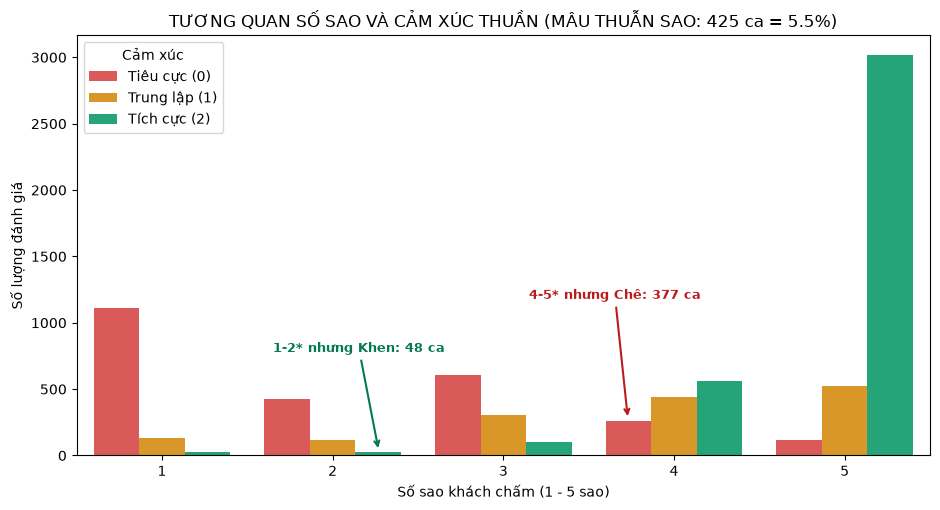

In [17]:
#Vẽ biểu đồ n_star vs sentiment nhấn mạnh các ca mâu thuẫn sao thật
plt.figure(figsize=(9.5, 5.2))
ax = sns.countplot(data=df_train, x='n_star', hue='sentiment', palette=['#EF4444', '#F59E0B', '#10B981'])
plt.title(f'TƯƠNG QUAN SỐ SAO VÀ CẢM XÚC THUẦN (MÂU THUẪN SAO: {n_contra} ca = {n_contra/len(df_train):.1%})')
plt.xlabel('Số sao khách chấm (1 - 5 sao)')
plt.ylabel('Số lượng đánh giá')
plt.legend(['Tiêu cực (0)', 'Trung lập (1)', 'Tích cực (2)'], title='Cảm xúc')
plt.annotate(f'1-2* nhưng Khen: {low_pos} ca', xy=(1.27, 35), xytext=(0.65, 780), arrowprops=dict(arrowstyle='->', color='#047857', lw=1.5), fontsize=9, fontweight='bold', color='#047857')
plt.annotate(f'4-5* nhưng Chê: {high_neg} ca', xy=(2.73, 275), xytext=(2.15, 1180), arrowprops=dict(arrowstyle='->', color='#B91C1C', lw=1.5), fontsize=9, fontweight='bold', color='#B91C1C')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_star_vs_sentiment.png'), dpi=300)
plt.show()

## 4. HEATMAP KHÍA CẠNH - CẢM XÚC (%) VÀ ĐA NHÃN ASP_0..ASP_4

In [18]:
#Chuẩn hóa theo tỷ lệ phần trăm từng hàng (%) để không bị thiên lệch cỡ nhóm
ct = pd.crosstab(df_train['aspect_group'], df_train['sentiment'])
ct.index = [asp_label_map[i] for i in ct.index]
ct.columns = ['Tiêu cực', 'Trung lập', 'Tích cực']
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
ct_pct.round(1)

,Tiêu cực,Trung lập,Tích cực
Hiệu năng & Cấu hình,40.7,20.1,39.2
Màn hình & Camera,34.8,19.0,46.3
Thời lượng Pin & Sạc,34.2,17.3,48.6
Giá cả & Hậu mãi,22.3,21.0,56.7
Thiết kế & Tổng quan,9.8,21.0,69.2


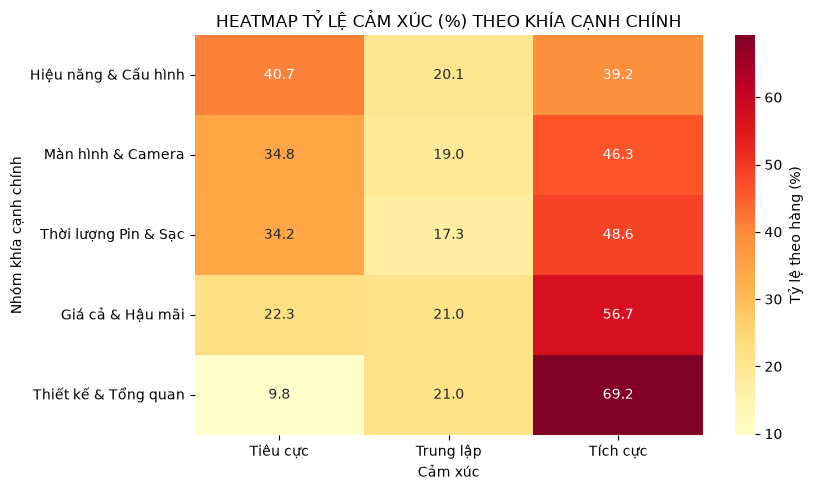

In [19]:
#Vẽ heatmap tỷ lệ phần trăm cảm xúc theo từng nhóm khía cạnh
plt.figure(figsize=(8.5, 5))
sns.heatmap(ct_pct, annot=True, fmt='.1f', cmap='YlOrRd', cbar_kws={'label': 'Tỷ lệ theo hàng (%)'})
plt.title('HEATMAP TỶ LỆ CẢM XÚC (%) THEO KHÍA CẠNH CHÍNH')
plt.xlabel('Cảm xúc')
plt.ylabel('Nhóm khía cạnh chính')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'eda_aspect_sentiment_heatmap.png'), dpi=300)
plt.show()

In [20]:
#Kiểm tra phân bố cảm xúc (%) trên từng nhãn đa khía cạnh asp_0..asp_4
rows_ml = []
for g in range(5):
    sub = df_train[df_train[f'asp_{g}'] == 1]
    vc = sub['sentiment'].value_counts(normalize=True) * 100
    rows_ml.append({'khia_canh': asp_label_map[g], 'so_cau': len(sub), 'tieu_cuc_%': round(vc.get(0, 0), 1), 'trung_lap_%': round(vc.get(1, 0), 1), 'tich_cuc_%': round(vc.get(2, 0), 1)})
pd.DataFrame(rows_ml)

,khia_canh,so_cau,tieu_cuc_%,trung_lap_%,tich_cuc_%
0,Hiệu năng & Cấu hình,5483,33.9,16.5,49.6
1,Màn hình & Camera,2686,24.5,14.1,61.4
2,Thời lượng Pin & Sạc,3595,25.8,15.2,58.9
3,Giá cả & Hậu mãi,3508,21.8,15.9,62.3
4,Thiết kế & Tổng quan,6138,26.0,20.4,53.7


In [21]:
#Ma trận đồng xuất hiện giữa 5 nhóm đa khía cạnh asp_0..asp_4
co_mat = df_train[asp_cols].T @ df_train[asp_cols]
co_mat.index = [asp_label_map[i] for i in range(5)]
co_mat.columns = [f'asp_{i}' for i in range(5)]
co_mat

,asp_0,asp_1,asp_2,asp_3,asp_4
Hiệu năng & Cấu hình,5483,2053,2594,2348,4202
Màn hình & Camera,2053,2686,1568,1270,2166
Thời lượng Pin & Sạc,2594,1568,3595,1613,2855
Giá cả & Hậu mãi,2348,1270,1613,3508,2931
Thiết kế & Tổng quan,4202,2166,2855,2931,6138


Tỷ lệ absa_4 != 0 trên Train (sau khi bỏ {OTHERS}): 70.05%
Train has_conflict: 1022 (13.17%) | conflict_with_neg: 607


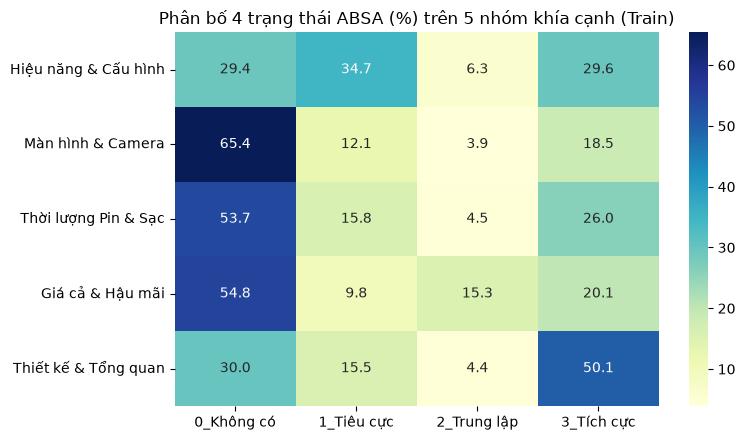

,0_Không có,1_Tiêu cực,2_Trung lập,3_Tích cực
Hiệu năng & Cấu hình,29.36,34.75,6.26,29.63
Màn hình & Camera,65.40,12.14,3.93,18.54
Thời lượng Pin & Sạc,53.68,15.81,4.48,26.02
Giá cả & Hậu mãi,54.81,9.82,15.32,20.06
Thiết kế & Tổng quan,29.95,15.52,4.42,50.10


In [22]:
#Thống kê True ABSA 5x4 (absa_4 != 0 sau khi bỏ {OTHERS}, xung đột nội bộ) và vẽ Heatmap 5x4 (%)
from src.labels import ABSA_COLS, ABSA_STATE_VI
print(f"Tỷ lệ absa_4 != 0 trên Train (sau khi bỏ {{OTHERS}}): {(df_train['absa_4'] != 0).mean():.2%}")
print(f"Train has_conflict: {int(df_train['has_conflict'].sum())} ({df_train['has_conflict'].mean():.2%}) | conflict_with_neg: {int(df_train['conflict_with_neg'].sum())}")
pct_5x4 = pd.DataFrame({
    asp_label_map[g]: (df_train[f'absa_{g}'].value_counts(normalize=True) * 100)
    for g in range(5)
}).fillna(0).reindex([0, 1, 2, 3]).T
pct_5x4.columns = [f'{i}_{ABSA_STATE_VI[i]}' for i in range(4)]
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(pct_5x4, annot=True, fmt='.1f', cmap='YlGnBu', ax=ax)
ax.set_title('Phân bố 4 trạng thái ABSA (%) trên 5 nhóm khía cạnh (Train)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_absa_5x4_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()
pct_5x4.round(2)


## 5. PHÂN BỐ ĐỘ DÀI TOKEN (WORD COUNT & PHOBERT BPE) CHỌN MAX_LEN

In [23]:
#Nạp PhoBERT tokenizer và đăng ký 5 special tokens PII giống lúc huấn luyện
from transformers import AutoTokenizer
tok_path = os.path.join(ROOT, 'models', 'phobert_multitask')
if not os.path.exists(os.path.join(tok_path, 'vocab.txt')):
    tok_path = 'vinai/phobert-base-v2'
tok = AutoTokenizer.from_pretrained(tok_path)
tok.add_special_tokens({'additional_special_tokens': ['[PHONE]', '[ORDER_ID]', '[EMAIL]', '[URL]', '[PERSON]']})
print('Loaded tokenizer:', tok_path, '| vocab size:', len(tok))

Loaded tokenizer: D:\E-commerce\models\phobert_multitask | vocab size: 64006


In [24]:
#Thử nghiệm đếm số từ và số BPE subword trên mẫu tempt
tempt = df_train['sentence_seg'].iloc[0]
len(tempt.split()), len(tok.encode(tempt, truncation=False))

(30, 39)

In [25]:
#Đo độ dài từ trên sentence_seg và BPE subwords PhoBERT trên toàn bộ tập train
df_train['seg_word_len'] = df_train['sentence_seg'].fillna('').astype(str).apply(lambda t: len(t.split()))
df_train['bpe_len'] = df_train['sentence_seg'].fillna('').astype(str).apply(lambda t: len(tok.encode(t, truncation=False)))

In [26]:
#In mean, p95, p99, max cho cả 128 & 256; kiểm tra cận trên mất câu >128 có Negative (luật quyết định > 1.0% train)
for col, name in [('seg_word_len', 'Word count (sentence_seg)'), ('bpe_len', 'PhoBERT BPE subwords')]:
    s = df_train[col]
    print(f"{name}: mean={s.mean():.2f}, p95={s.quantile(0.95):.0f}, p99={s.quantile(0.99):.0f}, max={s.max()}, <=128={(s <= 128).mean():.2%}, <=256={(s <= 256).mean():.2%}")
has_any_neg = (df_train[[f'absa_{g}' for g in range(5)]].values == 1).any(axis=1)
gt128_neg = int(((df_train['bpe_len'] > 128) & has_any_neg).sum())
gt128_neg_pct = gt128_neg / len(df_train)
print(f'Cận trên câu bpe_len > 128 có Negative: {gt128_neg}/{len(df_train)} ({gt128_neg_pct:.2%})')
print('Quyết định MAX_LEN_ABSA:', 'Dùng head+tail (>1%)' if gt128_neg_pct > 0.01 else 'Giữ MAX_LEN_ABSA=128 (<=1% train)')


Word count (sentence_seg): mean=36.64, p95=80, p99=110, max=187, <=128=99.64%, <=256=100.00%
PhoBERT BPE subwords: mean=40.87, p95=86, p99=119, max=200, <=128=99.37%, <=256=100.00%
Cận trên câu bpe_len > 128 có Negative: 33/7762 (0.43%)
Quyết định MAX_LEN_ABSA: Giữ MAX_LEN_ABSA=128 (<=1% train)


In [27]:
os.listdir(FIG_DIR)

['e02_learning_curve.png',
 'eda_aspect_dist.png',
 'eda_aspect_sentiment_heatmap.png',
 'eda_sentiment_dist.png',
 'eda_star_vs_sentiment.png',
 'fig_absa_5x4_heatmap.png',
 'r00_experiments_summary.png',
 'shap_top_negative_words.png']